# Fil rouge ProtAnnotML · 5 — Évaluer comme un relecteur : intervalles, tests appariés, stratification, abstention

> **Objectif** : transformer des prédictions en **résultats publiables**. On choisit les bonnes unités (résidu, domaine, borne), on calcule des intervalles de confiance par **bootstrap par cluster** (les domaines d'un même cluster de germlines ne sont pas indépendants), on compare deux méthodes par des **tests appariés**, on **stratifie** (identité à l'entraînement, mutation, locus), et on évalue la **prédiction sélective** (abstention) pour l'identification des gènes. On termine par une liste de contrôle pour l'article.

| | |
|---|---|
| **Durée estimée** | 2 h |
| **Prérequis** | Fil rouge 1–3 ; module 8 (bootstrap, calibration) |
| **Librairies** | `numpy`, `scipy`, `pandas`, `matplotlib` |

**Plan**

1. Les unités d'évaluation
2. Bootstrap : pourquoi par cluster
3. Comparer deux méthodes : tests appariés
4. Stratifier : là où les différences se cachent
5. Prédiction sélective : savoir dire « je ne sais pas »
6. Liste de contrôle pour l'article
7. Exercices

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))
DATA = Path("data_protannotml")
from protannotml.synth import load_jsonl
from protannotml.imgt import allele_key
from protannotml.splits import encode_aligned, identity_matrix, cluster_at

examples = {e["id"]: e for e in load_jsonl(DATA / "examples.jsonl")}
refs = load_jsonl(DATA / "reference_V.jsonl")
j_genes = load_jsonl(DATA / "reference_J.jsonl")
splits = json.loads((DATA / "splits.json").read_text())
pred = pd.read_csv(DATA / "baseline_predictions.csv")

# covariates of each test V domain: locus, species, mutation rate, germline cluster, max identity to training germlines
keys = [allele_key(r["species"], r["allele"]) for r in refs]
index = {k: i for i, k in enumerate(keys)}
I = identity_matrix(encode_aligned([r["positions"] for r in refs]))
_, cl80 = cluster_at(I, 0.80)


def domain_of(row):
    return next(d for d in examples[row.id]["domains"] if d["type"] == "V" and d["start"] == row.start)

cov_rows = []
for regime in pred.regime.unique():
    train_idx = np.array(sorted({index[allele_key(d["species"], d["v_allele"])] for i in splits[regime]["train"]
                                 for d in examples[i]["domains"] if d["type"] == "V"}))
    for row in pred[pred.regime == regime][["id", "start"]].drop_duplicates().itertuples():
        d = domain_of(row)
        k = index[allele_key(d["species"], d["v_allele"])]
        cov_rows.append(dict(regime=regime, id=row.id, start=row.start, locus=d["locus"], species=d["species"],
                             shm=d["shm_rate"], cluster=int(cl80[k]), max_identity=float(I[k, train_idx].max())))
cov = pd.DataFrame(cov_rows)
df = pred.merge(cov, on=["regime", "id", "start"])
df["exact"] = df.pos_correct == df.n
df["residue_acc"] = df.pos_correct / df.n
print(df.groupby(["regime", "method"]).agg(domains=("id", "size"), exact=("exact", "mean"), residue_acc=("residue_acc", "mean")).round(3).to_string())

                                                   domains  exact  residue_acc
regime           method                                                       
R2 cluster 80 %  alignement, répertoire complet        310  1.000        1.000
                 alignement, répertoire restreint      310  0.987        0.998
                 résidu + Viterbi monotone             310  0.687        0.995
                 résidu, argmax                        310  0.126        0.930
R3 espèce exclue alignement, répertoire complet        400  1.000        1.000
                 alignement, répertoire restreint      400  0.990        1.000
                 résidu + Viterbi monotone             400  0.622        0.994
                 résidu, argmax                        400  0.068        0.944


## 1. Les unités d'évaluation

Le choix de l'unité change le message :

| Unité | Métrique | Ce qu'elle dit | Piège |
|---|---|---|---|
| résidu | exactitude des positions / régions | qualité moyenne | dominée par les frameworks faciles (~80 % des résidus) |
| domaine | domaine **entièrement** exact | ce que vit l'utilisateur | sévère : une erreur sur 120 résidus = échec |
| borne | erreur en résidus sur chaque frontière (CDR, domaine) | utilité pratique (extraction des CDR) | à rapporter en distribution, pas en moyenne |
| ensemble | gène correct si dans l'ensemble des équivalents | identification honnête | sans ensembles, on pénalise des erreurs impossibles à éviter |

Rapporte **au moins** l'exactitude par résidu **et** par domaine, et la distribution des erreurs de bornes des CDR, **séparément par CDR** : le CDR3 concentre presque toutes les difficultés.

## 2. Bootstrap : pourquoi par cluster

Le bootstrap standard rééchantillonne les domaines comme s'ils étaient indépendants. Or deux domaines issus du même cluster de germlines ont des erreurs **corrélées** (si la méthode rate ce gène, elle le rate pour tous ses domaines). L'échantillon effectif est donc plus petit que le nombre de domaines, et l'intervalle naïf est **trop étroit**. Le bootstrap **par cluster** rééchantillonne des clusters entiers.

In [2]:
"""Evaluation statistics for ProtAnnotML: cluster bootstrap, paired comparisons, selective prediction."""
import numpy as np
from scipy import stats


def bootstrap_ci(values, groups=None, n_boot=2000, alpha=0.05, seed=0, statistic=np.mean):
    """Percentile CI of statistic(values). If groups is given, resample whole groups (cluster bootstrap)."""
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    if groups is None:
        idx = rng.integers(0, len(values), size=(n_boot, len(values)))
        boots = np.array([statistic(values[i]) for i in idx])
    else:
        groups = np.asarray(groups)
        uniq = np.unique(groups)
        members = {g: np.flatnonzero(groups == g) for g in uniq}
        boots = []
        for _ in range(n_boot):
            pick = rng.choice(uniq, size=len(uniq), replace=True)
            boots.append(statistic(values[np.concatenate([members[g] for g in pick])]))
        boots = np.array(boots)
    lo, hi = np.quantile(boots, [alpha / 2, 1 - alpha / 2])
    return float(statistic(values)), float(lo), float(hi)


def paired_bootstrap_diff(a, b, groups=None, n_boot=2000, seed=0):
    """CI and two-sided p-value for mean(a - b) on paired per-item scores, optionally by cluster."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    est, lo, hi = bootstrap_ci(d, groups, n_boot=n_boot, seed=seed)
    rng = np.random.default_rng(seed + 1)
    if groups is None:
        boots = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
    else:
        groups = np.asarray(groups); uniq = np.unique(groups)
        members = {g: np.flatnonzero(groups == g) for g in uniq}
        boots = np.array([d[np.concatenate([members[g] for g in rng.choice(uniq, len(uniq))])].mean() for _ in range(n_boot)])
    p = 2 * min((boots <= 0).mean(), (boots >= 0).mean())
    return est, lo, hi, max(p, 1 / n_boot)


def mcnemar_exact(correct_a, correct_b):
    """Exact McNemar test on paired binary outcomes (binomial test on discordant pairs)."""
    a, b = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    if n01 + n10 == 0:
        return n01, n10, 1.0
    return n01, n10, float(stats.binomtest(n10, n01 + n10, 0.5).pvalue)

In [3]:
from protannotml.stats import bootstrap_ci, paired_bootstrap_diff, mcnemar_exact

rows = []
for (regime, method), g in df.groupby(["regime", "method"]):
    if method == "résidu, argmax":
        continue
    est, lo, hi = bootstrap_ci(g.exact, None)
    _, clo, chi = bootstrap_ci(g.exact, g.cluster)
    rows.append(dict(regime=regime.split()[0], method=method, exact=round(est, 3), naive_CI=f"[{lo:.3f}, {hi:.3f}]",
                     cluster_CI=f"[{clo:.3f}, {chi:.3f}]", width_ratio=round((chi - clo) / max(hi - lo, 1e-9), 2),
                     n_domains=len(g), n_clusters=g.cluster.nunique()))
ci = pd.DataFrame(rows)
print(ci.to_string(index=False))

regime                           method  exact       naive_CI     cluster_CI  width_ratio  n_domains  n_clusters
    R2   alignement, répertoire complet  1.000 [1.000, 1.000] [1.000, 1.000]         0.00        310           7
    R2 alignement, répertoire restreint  0.987 [0.974, 0.997] [0.963, 1.000]         1.64        310           7
    R2        résidu + Viterbi monotone  0.687 [0.632, 0.739] [0.584, 0.831]         2.32        310           7
    R3   alignement, répertoire complet  1.000 [1.000, 1.000] [1.000, 1.000]         0.00        400          57
    R3 alignement, répertoire restreint  0.990 [0.980, 0.998] [0.981, 0.998]         0.96        400          57
    R3        résidu + Viterbi monotone  0.623 [0.575, 0.670] [0.547, 0.701]         1.62        400          57


Pour le modèle par résidu, l'intervalle par cluster est **nettement plus large** que l'intervalle naïf (2,3 fois en R2, 1,6 fois en R3) : ses erreurs se concentrent sur certains clusters de germlines. Remarque aussi la colonne `n_clusters` : le test R2 ne contient que **7** clusters. Avec si peu de clusters, même le bootstrap par cluster est fragile ; c'est un argument pour un test plus large (ou plusieurs tirages du découpage) et il faut le signaler. (Pour l'alignement avec répertoire complet, il n'y a presque aucune erreur, donc aucune variabilité à estimer : un intervalle [1,000 ; 1,000] ne veut pas dire « certitude », il veut dire « pas d'erreur observée » ; rapporte alors une borne, par exemple la règle de trois : avec $n$ succès sur $n$, le taux d'erreur est inférieur à $3/n$ à 95 %.)

## 3. Comparer deux méthodes : tests appariés

Les deux méthodes sont évaluées sur **les mêmes** domaines : on compare donc des différences **par domaine** (apparié), ce qui élimine la variabilité due à la difficulté de chaque domaine. Deux outils :
- le **bootstrap apparié** de la différence (par cluster), pour l'exactitude par résidu ;
- le **test de McNemar exact** pour une issue binaire (domaine exact ou non) : seules les paires **discordantes** comptent.

In [4]:
comparisons = []
for regime in df.regime.unique():
    g = df[df.regime == regime].pivot_table(index=["id", "start", "cluster"], columns="method", values=["residue_acc", "exact"])
    g = g.reset_index()
    for m_a, m_b in [("alignement, répertoire restreint", "résidu + Viterbi monotone"),
                     ("résidu + Viterbi monotone", "résidu, argmax")]:
        est, lo, hi, p = paired_bootstrap_diff(g[("residue_acc", m_a)], g[("residue_acc", m_b)], g["cluster"])
        n01, n10, p_mc = mcnemar_exact(g[("exact", m_a)].astype(bool), g[("exact", m_b)].astype(bool))
        comparisons.append(dict(regime=regime.split()[0], A=m_a, B=m_b, residue_acc_diff=f"{est:+.4f} [{lo:+.4f}, {hi:+.4f}]",
                                p_bootstrap=f"{p:.3g}", only_A_exact=n10, only_B_exact=n01, p_mcnemar=f"{p_mc:.2g}"))
print(pd.DataFrame(comparisons).to_string(index=False))

regime                                A                         B           residue_acc_diff p_bootstrap  only_A_exact  only_B_exact p_mcnemar
    R2 alignement, répertoire restreint résidu + Viterbi monotone +0.0032 [+0.0006, +0.0059]       0.015            95             2     6e-26
    R2        résidu + Viterbi monotone            résidu, argmax +0.0656 [+0.0315, +0.1266]      0.0005           174             0   8.4e-53
    R3 alignement, répertoire restreint résidu + Viterbi monotone +0.0057 [+0.0043, +0.0072]      0.0005           150             3     1e-40
    R3        résidu + Viterbi monotone            résidu, argmax +0.0497 [+0.0404, +0.0592]      0.0005           222             0     3e-67


Lecture : l'alignement (même avec un répertoire restreint) bat le modèle par résidu avec une différence nette et des centaines de paires discordantes dans le même sens ; le décodage contraint bat l'argmax de façon écrasante. Avec plusieurs comparaisons dans un article, **corrige** les p-valeurs (Holm) ou, mieux, rapporte les **intervalles** de différence : ils disent à la fois si l'écart est réel et s'il est important.

## 4. Stratifier : là où les différences se cachent

Un chiffre global mélange des situations très différentes. On trace l'exactitude par domaine selon l'**identité maximale de la germline à l'entraînement** (la variable clé du notebook 2), selon le **taux de mutation**, et par **locus**.

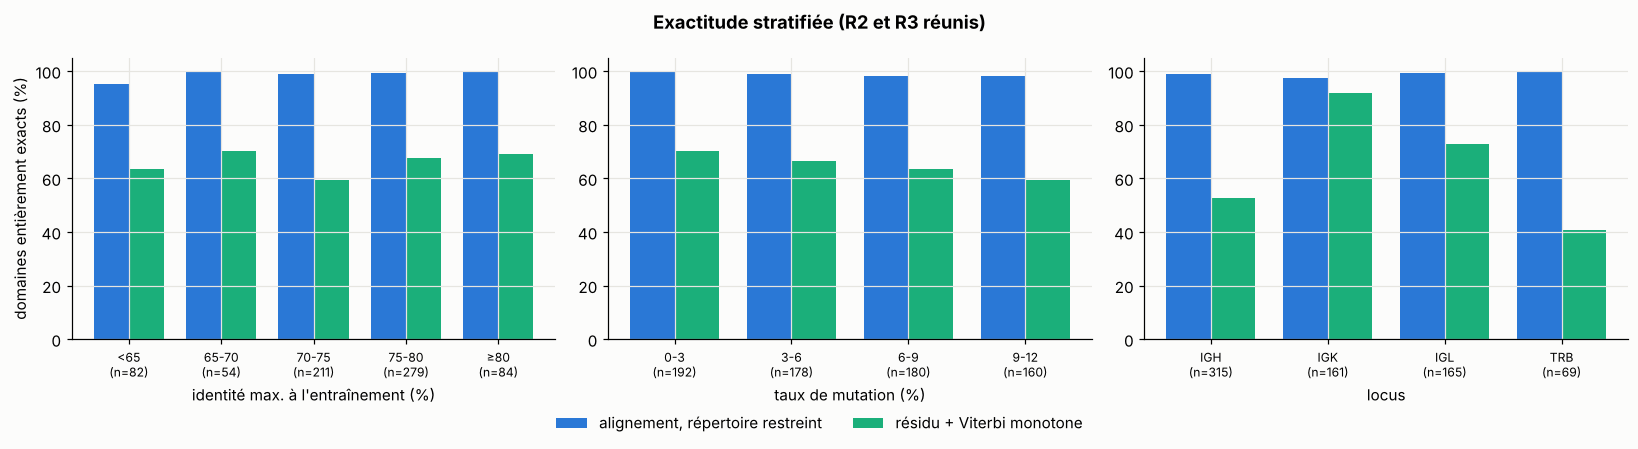

In [5]:
methods = ["alignement, répertoire restreint", "résidu + Viterbi monotone"]
sub = df[df.method.isin(methods)].copy()
sub["identity_bin"] = pd.cut(sub.max_identity * 100, [0, 65, 70, 75, 80, 101], labels=["<65", "65-70", "70-75", "75-80", "≥80"])
sub["shm_bin"] = pd.cut(sub.shm * 100, [-0.1, 3, 6, 9, 12.1], labels=["0-3", "3-6", "6-9", "9-12"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in [(axes[0], "identity_bin", "identité max. à l'entraînement (%)"), (axes[1], "shm_bin", "taux de mutation (%)"),
                       (axes[2], "locus", "locus")]:
    tab = sub.groupby([col, "method"], observed=True).exact.agg(["mean", "size"]).reset_index()
    cats = list(tab[col].drop_duplicates())
    x = np.arange(len(cats))
    for k, m in enumerate(methods):
        t = tab[tab.method == m].set_index(col).reindex(cats)
        ax.bar(x + (k - 0.5) * 0.38, t["mean"] * 100, 0.38, color=PALETTE[0] if k == 0 else PALETTE[2], label=m)
    sizes = tab[tab.method == methods[1]].set_index(col).reindex(cats)["size"]
    ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={int(n)})" for c, n in zip(cats, sizes)], fontsize=8)
    ax.set_xlabel(title); ax.set_ylim(0, 105)
axes[0].set_ylabel("domaines entièrement exacts (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Exactitude stratifiée (R2 et R3 réunis)", fontweight="bold")
plt.tight_layout(); plt.show()

Ce que la stratification révèle et que la moyenne cachait : le modèle par résidu se dégrade avec la mutation (de 70 % à 60 % de domaines exacts) et dépend fortement du locus (92 % pour IGK, 53 % pour IGH, 41 % pour TRB : les loci à CDR3 longs et variables sont les plus durs pour une fenêtre locale). En revanche, l'identité à l'entraînement a peu d'effet ici, ce qui suggère que ses erreurs viennent surtout des régions variables (le CDR3) plutôt que de la nouveauté des frameworks : c'est une hypothèse, à vérifier avec l'exercice 3. Deux bonnes pratiques visibles ici : afficher les **effectifs** de chaque strate (une barre calculée sur 15 domaines ne vaut pas une barre sur 300), et choisir les strates **avant** de regarder les résultats (sinon, on finit toujours par trouver une strate où son modèle gagne).

## 5. Prédiction sélective : savoir dire « je ne sais pas »

Pour T4, la question n'est pas seulement « quel est le gène ? », mais « **à quel point** la réponse est fiable ». Une méthode qui s'abstient quand elle n'est pas sûre est bien plus utile qu'une méthode qui répond toujours. On l'évalue par une **courbe risque–couverture** : on trie les prédictions par confiance décroissante, et pour chaque couverture (fraction des cas où l'on répond), on mesure le taux d'erreur.

Expérience : l'alignement avec répertoire restreint à l'entraînement, sur un mélange de domaines du test R1 (allèle exact exclu, mais le gène est le plus souvent présent par ses autres allèles) et du test R2 (gène toujours absent). La confiance est l'**identité** entre la séquence et la germline retenue. Une bonne confiance doit rejeter d'abord les cas R2.

In [6]:
from protannotml.align import GermlineAligner

mix = []
for regime, label in [("R1 par allèle", "test R1 (allèle exclu)"), ("R2 cluster 80 %", "test R2 (gène absent)")]:
    train_keys = {allele_key(d["species"], d["v_allele"]) for i in splits[regime]["train"] for d in examples[i]["domains"] if d["type"] == "V"}
    al = GermlineAligner([r for r in refs if allele_key(r["species"], r["allele"]) in train_keys], j_genes)
    pairs = [(examples[i], d) for i in splits[regime]["test"] for d in examples[i]["domains"] if d["type"] == "V"]
    rng = np.random.default_rng(0)
    for k in rng.choice(len(pairs), size=min(250, len(pairs)), replace=False):
        ex, d = pairs[k]
        q = ex["seq"][d["start"]:d["end"]]
        c, score, aln = al.best_germline(q)
        identity = np.mean([q[i] == al.v_seq[c][j] for i, j in aln])
        ok = al.v[c]["gene"] in d.get("gene_set", [d["v_gene"]]) and al.v[c]["species"] == d["species"]
        mix.append(dict(case=label, identity=identity, correct=ok, shm=d["shm_rate"]))
mix = pd.DataFrame(mix)
print(mix.groupby("case").agg(n=("correct", "size"), accuracy=("correct", "mean"), median_identity=("identity", "median")).round(3).to_string())

                          n  accuracy  median_identity
case                                                  
test R1 (allèle exclu)  250     0.612            0.921
test R2 (gène absent)   250     0.000            0.703


In [7]:
def risk_coverage(confidence, correct):
    """Sort by decreasing confidence; return coverage and error rate among the accepted predictions."""
    order = np.argsort(-np.asarray(confidence))
    c = np.asarray(correct, dtype=float)[order]
    k = np.arange(1, len(c) + 1)
    return k / len(c), 1 - np.cumsum(c) / k


def aurc(confidence, correct):
    """Area under the risk-coverage curve (lower is better)."""
    cov, risk = risk_coverage(confidence, correct)
    return float(np.mean(risk))

AUROC of identity for 'gene is correct': 0.997
answer only if identity >= 0.80: coverage 44%, error 30.8%, R2 (absent gene) cases still answered: 1
answer only if identity >= 0.85: coverage 38%, error 20.4%, R2 (absent gene) cases still answered: 0
answer only if identity >= 0.90: coverage 30%, error 4.0%, R2 (absent gene) cases still answered: 0


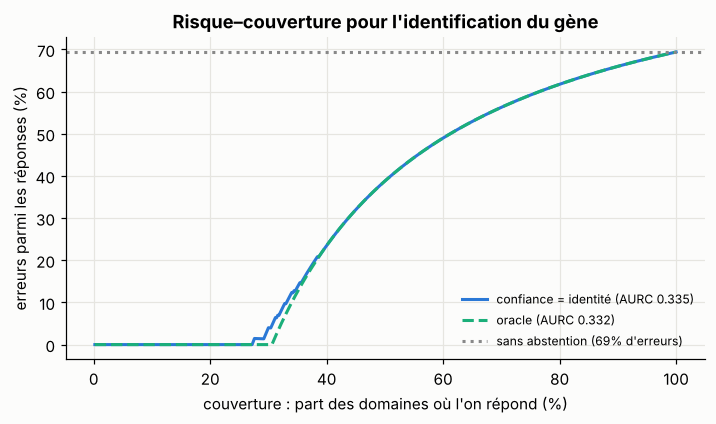

In [8]:
from protannotml.stats import risk_coverage, aurc
from sklearn.metrics import roc_auc_score

cov_, risk_ = risk_coverage(mix.identity, mix.correct)
oracle_cov, oracle_risk = risk_coverage(mix.correct.astype(float), mix.correct)
rand_risk = 1 - mix.correct.mean()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(cov_ * 100, risk_ * 100, color=PALETTE[0], label=f"confiance = identité (AURC {aurc(mix.identity, mix.correct):.3f})")
ax.plot(oracle_cov * 100, oracle_risk * 100, "--", color=PALETTE[2], label=f"oracle (AURC {aurc(mix.correct.astype(float), mix.correct):.3f})")
ax.axhline(rand_risk * 100, ls=":", color="#888", label=f"sans abstention ({rand_risk:.0%} d'erreurs)")
ax.set_xlabel("couverture : part des domaines où l'on répond (%)"); ax.set_ylabel("erreurs parmi les réponses (%)")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Risque–couverture pour l'identification du gène")
plt.show()
print(f"AUROC of identity for 'gene is correct': {roc_auc_score(mix.correct, mix.identity):.3f}")
for thr in [0.80, 0.85, 0.90]:
    acc = mix[mix.identity >= thr]
    print(f"answer only if identity >= {thr:.2f}: coverage {len(acc) / len(mix):.0%}, error {1 - acc.correct.mean():.1%}, "
          f"R2 (absent gene) cases still answered: {(acc.case == 'test R2 (gène absent)').sum()}")

Lecture, en deux temps :
- le **classement** est presque parfait ici (AUROC 0,997 ; la courbe colle à l'oracle) : sur ces données synthétiques, une identité élevée signifie presque toujours un gène correct ;
- mais le **seuil** décide de tout : à 0,80 d'identité, on répond à 44 % des domaines avec 31 % d'erreurs ; à 0,90, à 30 % des domaines avec 4 % d'erreurs. Attention aussi à l'étiquette « test R1 » : dans ce régime, les gènes à un seul allèle sont absents de l'entraînement, d'où 61 % d'exactitude seulement.

Sur de vraies données, la séparation sera moins nette (une forte mutation fait baisser l'identité de séquences dont le gène est connu ; un gène absent mais proche d'un gène connu garde une identité élevée). Pour ProtAnnotML, le critère est clair : la courbe risque–couverture du modèle doit être **sous** celle de l'alignement, à seuil choisi sur la validation. C'est un résultat que l'on peut afficher dans un article, et qui répond à un vrai besoin des utilisateurs (« dites-moi quand ne pas vous croire »).

## 6. Liste de contrôle pour l'article

| Élément | À rapporter |
|---|---|
| Données | version de la release IMGT, filtres, nombre de séquences par locus et espèce, ensembles d'ambiguïtés |
| Découpage | régime(s), seuil et méthode de clustering, distribution de l'identité max. test → entraînement |
| Références | alignement (IMGT/DomainGapAlign ou équivalent) **et** une baseline simple ; mêmes séquences de test |
| Métriques | par résidu **et** par domaine ; erreurs de bornes par CDR ; T4 avec ensembles ; risque–couverture |
| Incertitude | IC par bootstrap **par cluster** ; plusieurs graines d'entraînement (≥ 3) |
| Comparaisons | tests appariés (bootstrap de différence, McNemar), correction multiple ou intervalles |
| Stratification | identité à l'entraînement, mutation, locus, espèce, type de construction (strates fixées a priori) |
| Analyse d'erreurs | 20–50 erreurs examinées à la main, classées par cause |
| Coûts | temps par séquence (CPU/GPU), mémoire, matériel ; c'est un argument majeur face à l'alignement |
| Reproductibilité | code, configurations, graines, poids du modèle, jeu de test expertisé publié |

## 7. Exercices

1. **Règle de trois.** Pour l'alignement avec répertoire complet (0 erreur sur 310 domaines en R2), donne une borne supérieure à 95 % du taux d'erreur. Combien de domaines faudrait-il pour garantir moins de 0,1 % d'erreurs ?
2. **Graines.** Réentraîne la régression logistique du notebook 3 avec 5 sous-échantillons différents. Compare l'écart-type entre graines à la largeur de l'IC bootstrap. Lequel domine ?
3. **Erreurs de bornes.** Pour le modèle par résidu, calcule pour chaque CDR la distribution de l'erreur (en résidus) sur la borne de début et de fin. Quel CDR est le plus difficile ?
4. **Abstention calibrée.** Choisis le seuil d'identité sur une **validation** (pas sur le test) pour garantir au plus 2 % d'erreurs, puis mesure la couverture et l'erreur réelles sur le test.

<details><summary>Indications</summary>

1. Règle de trois : $3/310 \approx 1\%$ ; pour 0,1 %, il faut environ 3 000 domaines sans erreur.
4. C'est de la prédiction sélective avec garantie ; regarde aussi la prédiction conforme (*conformal prediction*) pour des garanties formelles sur les ensembles de gènes prédits.
</details>